# 02 - Data Preparation, Feature Engineering and Feature Selection

**Task 03, Part 1** (import, missing values, duplicates, feature engineering, feature selection, scaling).

**Rules we follow in this notebook (to avoid data leakage)**
- Duplicates are removed **before** the train/test split.
- The test set is created **now** and is **not touched again until notebook 03**. Every decision below uses **training data only**.
- Anything that *learns* from data (median imputation, scaling, one-hot categories) is fitted on training data only, inside a scikit-learn pipeline.
- Feature decisions are made from **experiments**, not guesses. Whatever the experiment shows, we report.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.svm import SVR

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.car_features import CarFeatureEngineer, RAW_INPUT_COLUMNS
from src.modeling import (CATEGORICAL_FEATURES, NUMERIC_FEATURES, RANDOM_STATE,
                          TARGET, build_pipeline, build_preprocessor)

DATA_PATH = ROOT / "data" / "raw" / "car_details_v3.csv"
PROCESSED = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

## 1. Import, remove duplicates, split

`random_state=42` makes the split reproducible. We use an 80/20 split, so the test set has about 1,400 cars, which is enough for a stable final score.

In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Raw rows: {len(raw)} | duplicates removed: {len(raw) - len(df)} | rows kept: {len(df)}")
assert len(df) >= 3000

X = df[RAW_INPUT_COLUMNS]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Save the split so notebook 03 uses EXACTLY the same rows
X_train.assign(**{TARGET: y_train}).to_csv(PROCESSED / "train.csv", index=False)
X_test.assign(**{TARGET: y_test}).to_csv(PROCESSED / "test.csv", index=False)
print("Saved data/processed/train.csv and test.csv")
print(f"Median price  train: {y_train.median():,.0f} | test: {y_test.median():,.0f}  (should be similar)")

Raw rows: 8128 | duplicates removed: 1202 | rows kept: 6926
Train: (5540, 11) | Test: (1386, 11)
Saved data/processed/train.csv and test.csv
Median price  train: 400,000 | test: 409,999  (should be similar)


## 2. Turning raw text into features (what `CarFeatureEngineer` does)

Left: raw text from the CSV. Right: what the model will actually see. The transformer is **stateless**, so running it on training data teaches it nothing and cannot leak information.

In [3]:
fe = CarFeatureEngineer()
feat_train = fe.fit_transform(X_train)

rows = X_train.index[:5]
print("RAW (text) ->")
display(X_train.loc[rows, ["name", "year", "km_driven", "mileage", "engine", "max_power"]])
print("PARSED (numbers + engineered) ->")
display(feat_train.loc[rows, ["brand", "car_age", "log_km_driven", "mileage", "engine", "max_power"]].round(2))

RAW (text) ->


,name,year,km_driven,mileage,engine,max_power
4855,Ford EcoSport 1.5 Diesel Titanium BSIV,2018,25000,23.0 kmpl,1498 CC,98.96 bhp
3143,Maruti Omni E 8 Str STD,2010,170000,NaN,NaN,NaN
4275,Hyundai i20 1.4 CRDi Asta,2011,75500,23.0 kmpl,1396 CC,90 bhp
2288,Maruti Swift Dzire VDi,2009,138000,19.3 kmpl,1248 CC,73.9 bhp
3914,Hyundai Accent DLS,2003,200000,13.1 kmpl,1493 CC,82 bhp


PARSED (numbers + engineered) ->


,brand,car_age,log_km_driven,mileage,engine,max_power
4855,Ford,2.0,10.13,23.0,1498.0,98.96
3143,Maruti,10.0,12.04,NaN,NaN,NaN
4275,Hyundai,9.0,11.23,23.0,1396.0,90.00
2288,Maruti,11.0,11.84,19.3,1248.0,73.90
3914,Hyundai,17.0,12.21,13.1,1493.0,82.00


## 3. Missing values

After parsing, invalid zeros and the blank " bhp" are also *missing*. We count them on the training set, then show what the median imputer will learn.

In [4]:
raw_missing = X_train[["mileage", "engine", "max_power", "seats"]].isna().sum()
parsed_missing = feat_train[["mileage", "engine", "max_power", "seats"]].isna().sum()
miss = pd.DataFrame({"missing_in_raw_file": raw_missing, "missing_after_parsing": parsed_missing})
miss["%_of_train"] = (miss["missing_after_parsing"] / len(feat_train) * 100).round(2)
display(miss)

# What the imputer learns - from TRAINING data only
imputer = SimpleImputer(strategy="median").fit(feat_train[["mileage", "engine", "max_power"]])
print("Medians the imputer will use to fill gaps (learned from train only):")
print(dict(zip(["mileage", "engine", "max_power"], imputer.statistics_.round(2))))
print("\nCategorical columns with missing values:", int(feat_train[CATEGORICAL_FEATURES].isna().sum().sum()))

,missing_in_raw_file,missing_after_parsing,%_of_train
mileage,172,184,3.32
engine,172,172,3.10
max_power,170,173,3.12
seats,172,172,3.10


Medians the imputer will use to fill gaps (learned from train only):
{'mileage': np.float64(19.4), 'engine': np.float64(1248.0), 'max_power': np.float64(81.83)}

Categorical columns with missing values: 0


**Decision:** fill numeric gaps with the **median** (robust to outliers) learned from training data, inside the pipeline. The test set and any new car from the app are filled with these same training medians.

## 4. Feature engineering: evidence

We engineered these features. For each, we check what it does rather than assuming it helps.

| Feature | How it is made | Why we tried it |
|---|---|---|
| `car_age` | 2020 minus `year` | Age is easier to reason about than a calendar year |
| `brand` | first word of `name` ("Land" -> "Land Rover") | `name` has ~2,000 values; brand has 32 |
| `log_km_driven` | `log(1 + km_driven)` | `km_driven` is extremely right-skewed |
| `km_per_year` | km_driven / max(age, 1) | usage intensity |
| `bhp_per_litre` | power / engine litres | engine "sportiness" |

In [5]:
print(f"Skewness of km_driven (train):     {feat_train['km_driven'].skew():.2f}")
print(f"Skewness of log_km_driven (train): {feat_train['log_km_driven'].skew():.2f}")
print(f"Skewness of km_per_year (train):   {feat_train['km_per_year'].skew():.2f}")

counts = feat_train["brand"].value_counts()
print(f"\nBrands in train: {len(counts)} | brands with < 10 rows (grouped as 'infrequent'): {int((counts < 10).sum())}")
print("Rare brands:", ", ".join(counts[counts < 10].index))

Skewness of km_driven (train):     5.02
Skewness of log_km_driven (train): -1.39
Skewness of km_per_year (train):   3.59

Brands in train: 30 | brands with < 10 rows (grouped as 'infrequent'): 11
Rare brands: Jaguar, Volvo, Isuzu, Kia, Ambassador, MG, Daewoo, Land Rover, Force, Peugeot, Opel


In [6]:
# Shared 5-fold cross-validation on the TRAINING set. The score is RMSLE
# (error on the log-price scale ~ typical % error). LOWER IS BETTER.
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_score(model, numeric, categorical, log_target=True):
    pipe = build_pipeline(model, numeric, categorical, log_target)
    r = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring={"rmsle": "neg_root_mean_squared_log_error", "r2": "r2",
                                "mae": "neg_mean_absolute_error"})
    return {"RMSLE": -r["test_rmsle"].mean(), "RMSLE_std": r["test_rmsle"].std(),
            "R2": r["test_r2"].mean(), "MAE": -r["test_mae"].mean()}

def rf(): return RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

base_num = ["car_age", "km_driven", "mileage", "engine", "max_power", "seats"]
experiments = {
    "A. parsed numbers, no brand":            (base_num, ["fuel", "seller_type", "transmission", "owner"]),
    "B. A + brand":                           (base_num, ["brand", "fuel", "seller_type", "transmission", "owner"]),
    "C. B, log(km) instead of km":            (["car_age", "log_km_driven", "mileage", "engine", "max_power", "seats"],
                                               ["brand", "fuel", "seller_type", "transmission", "owner"]),
    "D. C + km_per_year + bhp_per_litre":     (["car_age", "log_km_driven", "mileage", "engine", "max_power", "seats", "km_per_year", "bhp_per_litre"],
                                               ["brand", "fuel", "seller_type", "transmission", "owner"]),
}
results = {name: cv_score(rf(), n, c) for name, (n, c) in experiments.items()}
fe_table = pd.DataFrame(results).T.round(4)
display(fe_table)

,RMSLE,RMSLE_std,R2,MAE
"A. parsed numbers, no brand",0.2408,0.0103,0.8790,82906.1072
B. A + brand,0.2301,0.0107,0.8835,80993.9453
"C. B, log(km) instead of km",0.2302,0.0107,0.8825,80993.3317
D. C + km_per_year + bhp_per_litre,0.2300,0.0106,0.8804,81096.3509


**How to read this table:** a change only counts if it is clearly bigger than the fold-to-fold noise (`RMSLE_std`, about 0.01). Compare rows A and B, then B/C/D.

In [7]:
# Does modelling log(price) instead of price help?  (same features, Random Forest)
n_final, c_final = experiments["C. B, log(km) instead of km"]
log_res = cv_score(rf(), n_final, c_final, log_target=True)
raw_res = cv_score(rf(), n_final, c_final, log_target=False)
target_table = pd.DataFrame({"log(price) target": log_res, "raw price target": raw_res}).T.round(4)
display(target_table[["R2", "MAE", "RMSLE"]])

,R2,MAE,RMSLE
log(price) target,0.8825,80993.3317,0.2302
raw price target,0.8831,81965.7956,0.2341


## 5. Scaling

Scaling puts numeric features on a common scale (mean 0, standard deviation 1). SVR is distance-based and needs it; tree models do not, so for them it is harmless. We scale **inside the pipeline**, fitted on training data only.

In [8]:
prep = build_preprocessor()
Z_train = prep.fit_transform(feat_train)
names = prep.get_feature_names_out()
print("Transformed training matrix:", Z_train.shape, "(rows, columns after imputing, scaling and one-hot encoding)")

num_mask = [n in NUMERIC_FEATURES for n in names]
check = pd.DataFrame(Z_train[:, num_mask], columns=np.array(names)[num_mask]).agg(["mean", "std"]).round(3)
display(check)
print("Numeric columns have mean ~0 and std ~1 on the training data, as expected.")
print("One-hot columns created:", int(len(names) - sum(num_mask)))

Transformed training matrix: (5540, 36) (rows, columns after imputing, scaling and one-hot encoding)


,car_age,log_km_driven,mileage,engine,max_power
mean,0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


Numeric columns have mean ~0 and std ~1 on the training data, as expected.
One-hot columns created: 31


## 6. Feature selection

We use **three independent checks** on training data, then decide:
1. **Correlation between features**: are some features near-copies of each other?
2. **Mutual information with price**: which features carry any signal (screening only)?
3. **Drop-one-feature test (ablation)**: remove one feature at a time and re-run cross-validation. If the score does not get worse, the feature is not helping.

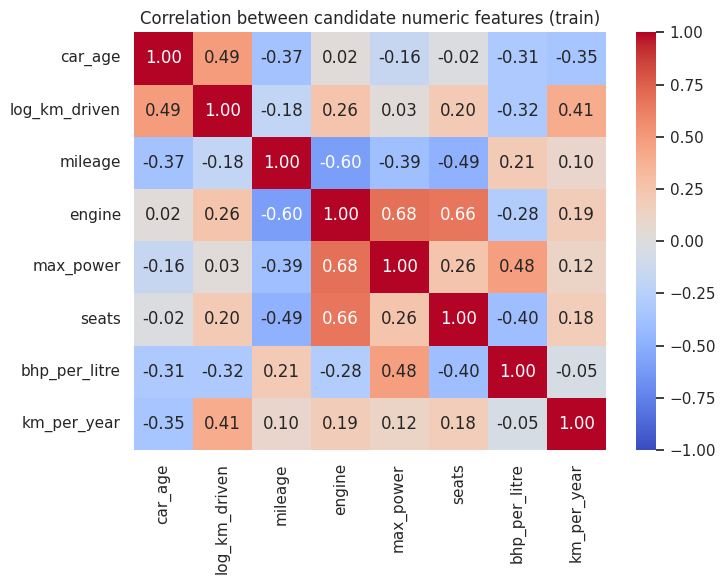

Feature pairs with |correlation| >= 0.6:


,feature_1,feature_2,corr
28,engine,max_power,0.68
29,engine,seats,0.66


In [9]:
cand_num = ["car_age", "log_km_driven", "mileage", "engine", "max_power", "seats", "bhp_per_litre", "km_per_year"]
cand_cat = ["brand", "fuel", "seller_type", "transmission", "owner"]

# 6.1 Correlation between candidate numeric features (pairwise, training data)
corr = feat_train[cand_num].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between candidate numeric features (train)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fs_feature_correlation.png", dpi=130, bbox_inches="tight")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
         .rename("corr").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
print("Feature pairs with |correlation| >= 0.6:")
display(pairs[pairs["corr"].abs() >= 0.6].sort_values("corr", key=abs, ascending=False).round(2))

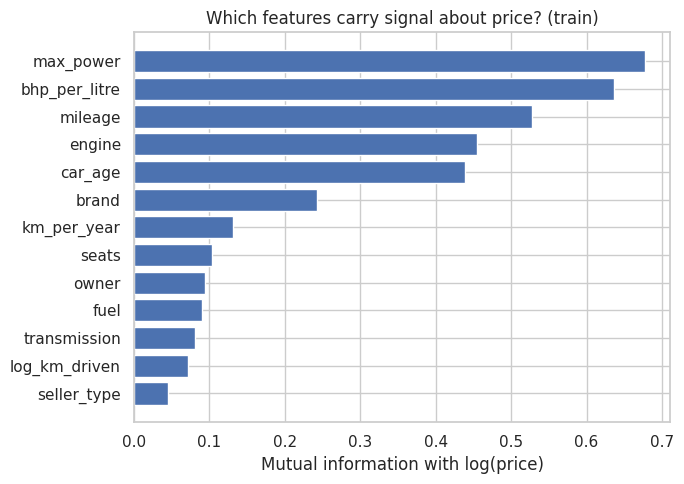

max_power        0.677
bhp_per_litre    0.636
mileage          0.527
engine           0.454
car_age          0.438
brand            0.242
km_per_year      0.131
seats            0.103
owner            0.094
fuel             0.089
transmission     0.080
log_km_driven    0.072
seller_type      0.045


In [10]:
# 6.2 Mutual information between each feature and log(price)  (screening only)
Z = feat_train[cand_num].copy()
Z = Z.fillna(Z.median())                       # medians from TRAIN only
for c in cand_cat:
    Z[c] = feat_train[c].astype("category").cat.codes
discrete = [False] * len(cand_num) + [True] * len(cand_cat)
mi = mutual_info_regression(Z, np.log1p(y_train), discrete_features=discrete, random_state=RANDOM_STATE)
mi_s = pd.Series(mi, index=Z.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(mi_s.index, mi_s.values, color="#4C72B0")
ax.set_xlabel("Mutual information with log(price)")
ax.set_title("Which features carry signal about price? (train)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fs_mutual_information.png", dpi=130, bbox_inches="tight")
plt.show()
print(mi_s.sort_values(ascending=False).round(3).to_string())

*Caution:* mutual information tends to favour columns with many distinct values (`brand`, `km_per_year`), so we treat it as a screening tool only. The ablation below is the stronger test.

,feature_removed,RMSLE,change_vs_full
0,(none - all 11),0.2302,0.0000
1,car_age,0.3068,0.0765
2,log_km_driven,0.2330,0.0027
3,mileage,0.2357,0.0055
4,engine,0.2319,0.0017
5,max_power,0.2419,0.0116
6,seats,0.2305,0.0003
7,brand,0.2409,0.0107
8,fuel,0.2318,0.0016
9,seller_type,0.2304,0.0002


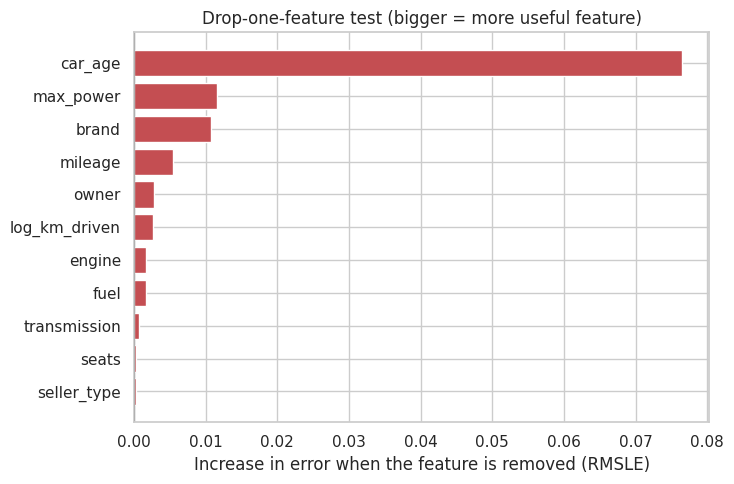

In [11]:
# 6.3 Drop-one-feature test (ablation) with a Random Forest, 5-fold CV on TRAIN
num_set = ["car_age", "log_km_driven", "mileage", "engine", "max_power", "seats"]
cat_set = ["brand", "fuel", "seller_type", "transmission", "owner"]
full = cv_score(rf(), num_set, cat_set)

rows = [{"feature_removed": "(none - all 11)", "RMSLE": full["RMSLE"], "change_vs_full": 0.0}]
for f in num_set + cat_set:
    r = cv_score(rf(), [x for x in num_set if x != f], [x for x in cat_set if x != f])
    rows.append({"feature_removed": f, "RMSLE": r["RMSLE"], "change_vs_full": r["RMSLE"] - full["RMSLE"]})
ablation = pd.DataFrame(rows).round(4)
display(ablation)

plot_df = ablation.iloc[1:].sort_values("change_vs_full")
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(plot_df["feature_removed"], plot_df["change_vs_full"], color="#C44E52")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Increase in error when the feature is removed (RMSLE)")
ax.set_title("Drop-one-feature test (bigger = more useful feature)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fs_ablation.png", dpi=130, bbox_inches="tight")
plt.show()

In [12]:
# 6.4 Joint check: does removing the two least useful features hurt ANY model type?
reduced_num = ["car_age", "log_km_driven", "mileage", "engine", "max_power"]            # no `seats`
reduced_cat = ["brand", "fuel", "transmission", "owner"]                                 # no `seller_type`
models = {
    "Random Forest":     lambda: RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": lambda: GradientBoostingRegressor(random_state=RANDOM_STATE),
    "SVR":               lambda: SVR(C=3.0),
}
rows = []
for mname, make in models.items():
    a = cv_score(make(), num_set, cat_set)
    b = cv_score(make(), reduced_num, reduced_cat)
    rows.append({"model": mname, "RMSLE_all_11": a["RMSLE"], "RMSLE_reduced_9": b["RMSLE"],
                 "difference": b["RMSLE"] - a["RMSLE"], "fold_noise_(std)": a["RMSLE_std"]})
joint = pd.DataFrame(rows).round(4)
display(joint)

,model,RMSLE_all_11,RMSLE_reduced_9,difference,fold_noise_(std)
0,Random Forest,0.2302,0.2305,0.0003,0.0107
1,Gradient Boosting,0.2345,0.2342,-0.0002,0.0088
2,SVR,0.2296,0.2305,0.0009,0.0133


## 7. Final feature set

The final decision is stored in `src/modeling.py` so that training, the tests and the Streamlit app all use the same lists. The cell below checks that the code matches the decision made in this notebook.

In [13]:
FINAL_NUMERIC = ["car_age", "log_km_driven", "mileage", "engine", "max_power"]
FINAL_CATEGORICAL = ["brand", "fuel", "transmission", "owner"]
assert NUMERIC_FEATURES == FINAL_NUMERIC and CATEGORICAL_FEATURES == FINAL_CATEGORICAL, "src/modeling.py is out of sync"
print("Final numeric features:    ", FINAL_NUMERIC)
print("Final categorical features:", FINAL_CATEGORICAL)
print("Not used: seats, seller_type (no measurable benefit), torque (unreliable text), km_driven (replaced by log version),")
print("          km_per_year, bhp_per_litre (no measurable benefit), name (replaced by brand).")

Final numeric features:     ['car_age', 'log_km_driven', 'mileage', 'engine', 'max_power']
Final categorical features: ['brand', 'fuel', 'transmission', 'owner']
Not used: seats, seller_type (no measurable benefit), torque (unreliable text), km_driven (replaced by log version),
          km_per_year, bhp_per_litre (no measurable benefit), name (replaced by brand).


## 8. Summary of results and decisions

**Measured on the training data (numbers copied from the outputs above)**

| Step | Result |
|---|---|
| Duplicates | 1,202 removed from 8,128 rows, leaving **6,926** |
| Split | 5,540 train / 1,386 test (80/20, `random_state=42`). Median price: 400,000 (train) vs 409,999 (test) |
| Missing after parsing (train) | `mileage` 184 (3.3%), `engine` 172 (3.1%), `max_power` 173 (3.1%), `seats` 172 (3.1%) |
| Imputer medians (train only) | mileage 19.4, engine 1,248 CC, max_power 81.83 bhp |
| Skewness of `km_driven` | 5.02 raw, -1.39 after `log(1+x)` |
| Brands in train | 30, of which 11 have fewer than 10 rows and are grouped as "infrequent" |
| After preprocessing | 5,540 rows x 36 columns (5 numeric + 31 one-hot); numeric columns have mean 0 and std 1 |

**Feature engineering experiments (Random Forest, 5-fold CV, lower RMSLE is better)**

- Adding `brand` improved the error from 0.2408 to 0.2301 (R2 0.879 to 0.884, MAE 82,906 to 80,994). This is a modest gain, about the size of one fold-to-fold standard deviation, and it agrees with the drop-one test below, where `brand` is the third most important feature.
- Replacing `km_driven` with `log_km_driven` made **no measurable difference** for a Random Forest (0.2301 vs 0.2302). That is expected: trees ignore monotonic transforms. We keep the log version because the skew (5.02) is a known problem for distance-based models such as SVR.
- `km_per_year` and `bhp_per_litre` also made **no measurable difference** (0.2300). We tested them, they did not help, so they are **not used**.
- Modelling log(price) instead of price: RMSLE 0.2302 vs 0.2341 and MAE 80,993 vs 81,966 in favour of log, while R2 is essentially equal (0.8825 vs 0.8831). The effect is small for a Random Forest, so we keep log(price) mainly because it matches our selection metric (relative error) and suits SVR.

**Feature selection**

- *Correlation:* only two pairs reach 0.6 (engine-max_power 0.68, engine-seats 0.66). No pair is above 0.7, so no feature is removed for redundancy alone.
- *Mutual information* ranks `max_power` (0.68), `bhp_per_litre` (0.64), `mileage` (0.53), `engine` (0.45) and `car_age` (0.44) highest, and `seller_type` (0.05) lowest. **This ranking disagrees with the drop-one test on `car_age`.** The reason: mutual information measures each feature on its own (newer cars simply tend to have higher power and mileage, so those carry "age" information too), while the drop-one test measures what a feature adds *beyond all the others*. For deciding what to remove, the drop-one test is the more relevant evidence.
- *Drop-one test* (rise in RMSLE when a feature is removed): `car_age` +0.0765, `max_power` +0.0116, `brand` +0.0107, `mileage` +0.0055, `owner` +0.0028, `log_km_driven` +0.0027, `engine` +0.0017, `fuel` +0.0016, `transmission` +0.0007, **`seats` +0.0003, `seller_type` +0.0002**.
- *Joint check:* removing `seats` and `seller_type` together changed RMSLE by +0.0003 (Random Forest), -0.0002 (Gradient Boosting) and +0.0009 (SVR), all far below the fold noise of 0.009 to 0.013.

**Final decision**

- **Used:** `car_age`, `log_km_driven`, `mileage`, `engine`, `max_power`, `brand`, `fuel`, `transmission`, `owner` (9 features).
- **Not used:** `seats` and `seller_type` (no measurable benefit), `torque` (unreliable free text), `km_driven` (replaced by the log version), `km_per_year` and `bhp_per_litre` (tested, no benefit), `name` (replaced by `brand`).
- We kept `fuel`, `transmission` and `engine` even though their drop-one effect is small: the threshold we used for removal was deliberately strict (about 0.0003 or less), and these three have an obvious real-world link to price.

**Limits of this analysis**
- The drop-one test uses one model family (Random Forest) and one set of folds. The joint check on three model types reduces, but does not remove, that risk.
- A feature that does not help *this* model on *this* data may still matter in other settings (for example, `seller_type` may matter more with a different dataset).